<a href="https://colab.research.google.com/github/chaimaao0/ml-data-science-internship/blob/main/housing_price_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Real Estate Housing Price Prediction (OLS, Ridge & Lasso)


## 1. Import Libraries

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## 2. Load the Data


In [6]:
df = pd.read_csv("/content/sample_data/housing.csv")
print("Shape:", df.shape)
df.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


**Missing values.** We check which columns have empty values.

In [7]:
df.isnull().sum()


,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


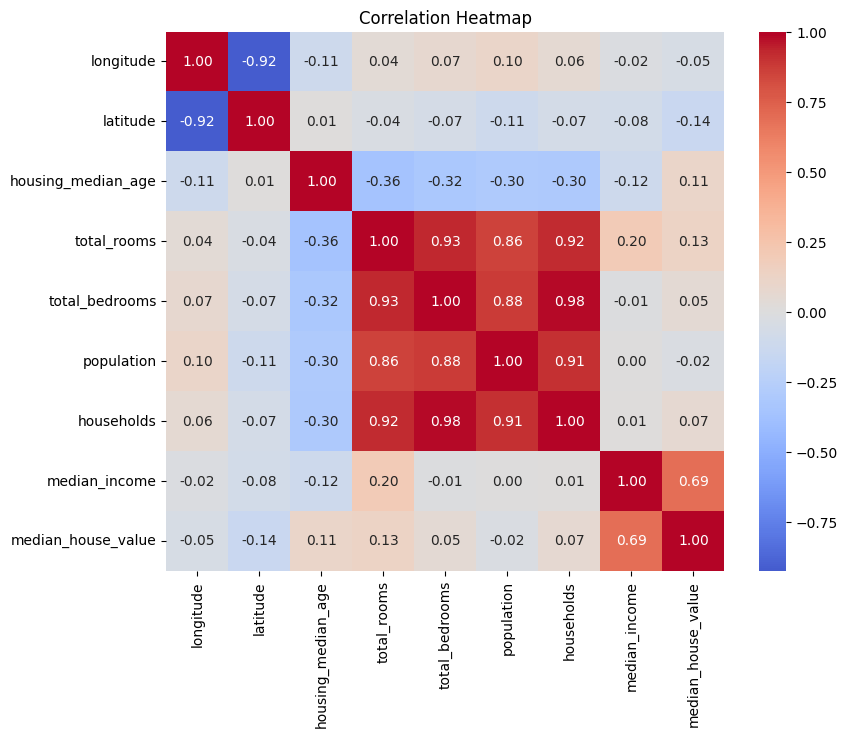

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

## 3. Feature Engineering
We create ratio features and two **interaction features** (a product of two features).

In [10]:
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]
df["income_x_age"] = df["median_income"] * df["housing_median_age"]
df["income_x_rooms"] = df["median_income"] * df["rooms_per_household"]

## 4. Handle Multicollinearity


In [11]:
corr = df.drop(columns="median_house_value").select_dtypes("number").corr()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
upper[upper.abs() > 0.8].sort_values(ascending=False)

total_bedrooms  households        0.979728
total_rooms     total_bedrooms    0.930380
                households        0.918484
population      households        0.907222
total_bedrooms  population        0.877747
median_income   income_x_rooms    0.869603
total_rooms     population        0.857126
longitude       latitude         -0.924664
dtype: float64

In [12]:
df = df.drop(columns="total_bedrooms")

## 5. Encode, Split, Impute and Standardize

In [13]:
df = pd.get_dummies(df, columns=["ocean_proximity"], drop_first=True, dtype=int)

X = df.drop(columns="median_house_value")
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (16512, 16) | Test: (4128, 16)


In [14]:

imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)

print("Missing values left:", X_train.isnull().sum().sum() + X_test.isnull().sum().sum())

Missing values left: 0


In [16]:
dummy_cols = [c for c in X.columns if c.startswith("ocean_proximity_")]
continuous_cols = [c for c in X.columns if c not in dummy_cols]
scaler = StandardScaler()
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_test[continuous_cols] = scaler.transform(X_test[continuous_cols])

## 6. Train the Models



In [17]:
ols = LinearRegression().fit(X_train, y_train)

In [18]:
alphas = [0.01, 0.1, 1, 10, 100, 1000]

ridge_grid = GridSearchCV(Ridge(), {"alpha": alphas}, cv=5, scoring="neg_root_mean_squared_error")
ridge_grid.fit(X_train, y_train)

lasso_grid = GridSearchCV(Lasso(max_iter=10000), {"alpha": alphas}, cv=5, scoring="neg_root_mean_squared_error")
lasso_grid.fit(X_train, y_train)

print("Best alpha for Ridge:", ridge_grid.best_params_["alpha"])
print("Best alpha for Lasso:", lasso_grid.best_params_["alpha"])

Best alpha for Ridge: 1
Best alpha for Lasso: 1


## 7. Evaluation (RMSE, MAE, R²)

In [19]:
preds = {
    "OLS": ols.predict(X_test),
    "Ridge": ridge_grid.predict(X_test),
    "Lasso": lasso_grid.predict(X_test),
}

results = pd.DataFrame({
    name: {"RMSE": np.sqrt(mean_squared_error(y_test, p)),
           "MAE": mean_absolute_error(y_test, p),
           "R2": r2_score(y_test, p)}
    for name, p in preds.items()
}).T

results.round(4)

,RMSE,MAE,R2
OLS,68831.1997,49450.9415,0.6385
Ridge,68840.6853,49457.2762,0.6384
Lasso,68832.5363,49451.4644,0.6384


## 8. Predicted vs Actual

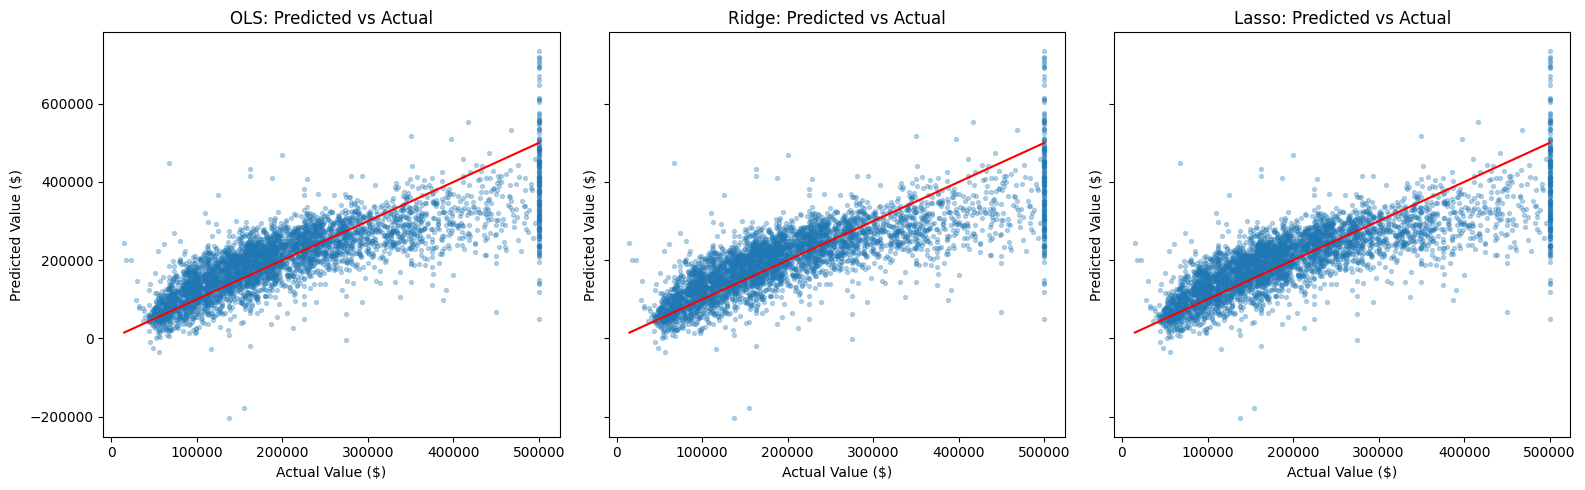

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.3, s=8)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
    ax.set_title(f"{name}: Predicted vs Actual")
    ax.set_xlabel("Actual Value ($)")
    ax.set_ylabel("Predicted Value ($)")
plt.tight_layout()
plt.show()

## 9. Residual Distribution

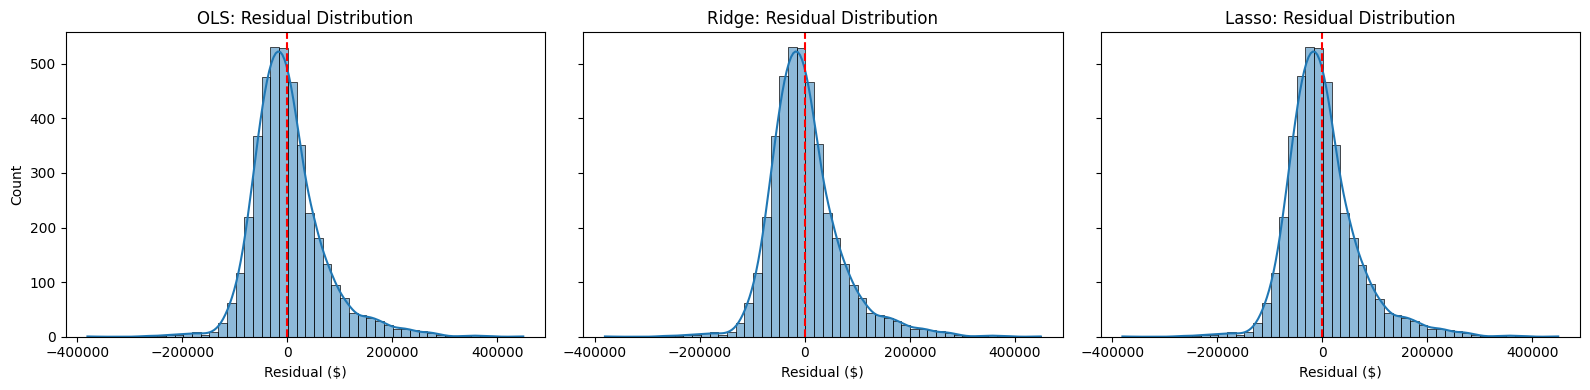

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharex=True, sharey=True)
for ax, (name, p) in zip(axes, preds.items()):
    sns.histplot(y_test - p, bins=50, kde=True, ax=ax)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_title(f"{name}: Residual Distribution")
    ax.set_xlabel("Residual ($)")
plt.tight_layout()
plt.show()

## 10. Conclusion
The three models performed almost the same on the test set: OLS had an RMSE of 68,831, Ridge 68,841 and Lasso 68,833, with an R² of about 0.64 for all of them. OLS was very slightly the best, but the difference is only a few dollars, so it is not meaningful. The best alpha for both Ridge and Lasso was 1.

Regularization did not improve the results here because the dataset is large (20,640 districts) and has few features, so OLS does not overfit. Ridge and Lasso are more useful when there are many or strongly correlated features.

An R² of 0.64 means the models explain about 64% of the variation in house prices. The residual plots show errors centered on zero but with a longer right tail, so the models under-predict some expensive houses. The price cap at 500,000 and the fact that all three models are linear limit the accuracy. As a next step, a non-linear model such as Random Forest could be tried.